# AR(2): Eigenvalue Decomposition

Until now we have only looked at a simple equation where the value of a variable at time $t$ depends only on its value at time $t - 1$. But what will happen if the value
of the variable at time $t$ not only depends on its value during the previous period but also on value of the period before that (at time $t - 2$)? In this case our
equation of motion will look like this (we will leave out the inhomogeneous part for simplicity):

:::{.ex-class}
$$
x_t = \phi_1 x_{t - 1} + \phi_2 x_{t - 2}
$$
:::

How can we solve this equation? It turns out that there is an elegant approach
because we can represent the second order equation of a system of vector equations of first order.

:::{.ex-class}
$$
\begin{align*}
x_t & = \phi_1 x_{t - 1} + \phi_2 x_{t - 2}\\
x_{t - 1} & = x_{t - 1}\\
\end{align*}
$$
:::

At a first glance we have not done anything useful. But the usefulness of this approach becomes apparent if we write the two equations above in matrix form.

$$
\begin{pmatrix}
x_t \\
x_{t - 1}
\end{pmatrix}
=
\begin{pmatrix}

\phi_1 & \phi_2 \\
1 & 0
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
$$

Note that we have not done anything special, we have just rewritten the same equation in a different form.

Now we can begin thinking how to reduce this problem to the one that we already know how to solve (which is the first order case).
If we could somehow transform the equations so that we have only $x_t$ and $x_{t - 1}$ in one of the equations and 
$x_{t - 1}$ and $x_{t - 2}$ in the other equation then we would be done, because we would have two equations
of the form that we already know how to solve.

Before we do, let's review a little bit of linear algebra.

:::{.ex-class}
- [What does does it mean to multiply a vector by a matrix?](https://www.desmos.com/calculator/ljm5qdlxav)
- [What are eigenvalues and eigenvectors?](https://www.desmos.com/calculator/vewpvnxrvj)
:::

Let's see this in action with a numerical example.

With $\phi_1 = 0.5$ and $\phi_2 = 0.1$ the system of equations is:

$$
\begin{pmatrix}
x_t \\
x_{t - 1}
\end{pmatrix}
=
\begin{pmatrix}
0.5 & 0.1 \\
1 & 0
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
$$

Next, I claim that the matrix 

$$
\begin{pmatrix}
0.5 & 0.4 \\
1 & 0
\end{pmatrix}
$$

can be decomposed as follows:

$$
\begin{pmatrix}
0.5 & 0.4 \\
1 & 0
\end{pmatrix} = 

\begin{pmatrix}
0.68 & -0.39 \\
0.73 & 0.92 
\end{pmatrix}
\begin{pmatrix}
0.93 & 0 \\
0 & -0.43
\end{pmatrix}
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
$$

Ok, it is absolutely not obvious that this is true. But you can check it by
simply doing the matrix multiplications on the right hand side.
You will get the matrix on the left hand side (up to rounding errors, because I rounded the numbers in the matrices to save space).


In [ ]:
# Check that the decomposition is correct (up to rounding errors)

import numpy as np
import matplotlib.pyplot as plt

# Define the first matrix on the right-hand side in the last equation
G1 = np.array([
    [ 0.68, -0.39],
    [0.73,  0.92]
])

# Define the middle matrix 
L = np.array([
    [0.93, 0],
    [0, -0.43]
])

# Define the last matrix
G2 = np.array([
    [1.0,  0.43],
    [-0.80,  0.74]
])

# Now multiply the three matrices to and 
# compare the result with the left-hand side 
# The result is rounded to two decimal places

(G1 @ L @ G2).round(2)

array([[ 0.5,  0.4],
       [ 1. , -0. ]])

Now that we have decomposed the matrix, we can show rewrite the
equation to by replacing the matrix with its decomposition (the three matrices).

$$
\begin{pmatrix}
x_t \\
x_{t - 1}
\end{pmatrix}
=
\begin{pmatrix}
0.68 & -0.39 \\
0.73 & 0.92
\end{pmatrix}
\begin{pmatrix}
0.93 & 0 \\
0 & -0.43
\end{pmatrix}
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
$$

Now we will pre-multiply both sides of the equation by the third matrix in the decomposition

$$
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
$$

to get:

$$
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
=
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
0.68 & -0.39 \\
0.73 & 0.92
\end{pmatrix}
\begin{pmatrix}
0.93 & 0 \\
0 & -0.43
\end{pmatrix}
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
$$



Again, it is still not obvious why we do this, but take some time to actually do the matrix multiplication. When you do this, you will notice something strange. The product of the first two matrices on the right-hand
unexpectedly turns out to be the identity matrix.

$$
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
0.68 & -0.39 \\
0.73 & 0.92
\end{pmatrix}
= \begin{pmatrix}
1 \cdot 0.68 + 0.43 \cdot 0.73 & 1 \cdot -0.39 + 0.43 \cdot 0.92 \\
-0.8 \cdot 0.68 + 0.74 \cdot 0.73 & -0.8 \cdot (-0.39) + 0.74 \cdot 0.92 
\end{pmatrix}
= \begin{pmatrix}
1 & 0 \\
0 & 1 \\
\end{pmatrix}
$$

In [13]:
# Check it with numpy

(G2 @ G1).round(1)

array([[ 1.,  0.],
       [-0.,  1.]])

The equation therefore simplifies to:

$$
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
=
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix}
\begin{pmatrix}
0.93 & 0 \\
0 & -0.43
\end{pmatrix}
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
$$

And we can skip the identity matrix as it does not change anything:

$$
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
=
\begin{pmatrix}
0.93 & 0 \\
0 & -0.43
\end{pmatrix}
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
$$


Let us look at the matrix multiplying the x vector on the left hand side which also appears as the last matrix/vector multiplication on the right hand side. Let's call
the product $\mathbf{z}_t$.

$$
\mathbf{z}_t = \begin{pmatrix}
\tilde{x}_t \\
\tilde{x}_{t - 1}
\end{pmatrix}
=
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
= \begin{pmatrix}
x_t + 0.43 x_{t - 1} \\
-0.80 x_{t - 1} + 0.74 x_{t - 2}
\end{pmatrix}
$$

$$
\mathbf{z}_{t - 1} = \begin{pmatrix}
\tilde{x}_{t - 1} \\
\tilde{x}_{t - 2}
\end{pmatrix}
=
\begin{pmatrix}
1.00 & 0.43 \\
-0.80 & 0.74
\end{pmatrix}
\begin{pmatrix}
x_{t - 1} \\
x_{t - 2}
\end{pmatrix}
= \begin{pmatrix}
x_{t - 1} + 0.43 x_{t - 2} \\
-0.80 x_{t - 2} + 0.74 x_{t - 3}
\end{pmatrix}
$$

Plug these two equations into the equation above to obtain:

$$
\begin{pmatrix}
\tilde{x}_t \\
\tilde{x}_{t - 1}
\end{pmatrix}
= 
\begin{pmatrix}
0.93 & 0 \\
0 & -0.43
\end{pmatrix}
\begin{pmatrix}
\tilde{x}_{t - 1} \\
\tilde{x}_{t - 2}
\end{pmatrix}
$$

Or more compactly:

$$
\mathbf{z}_t = \mathbf{\Lambda} \mathbf{z}_{t - 1}
$$

Now, you may wonder why we did all this. The whole point of the transformation was that the system of transformed has a very simple structure.
See what happens when we investigate the stability of the transformed system by substituting for $\mathbf{z}_{t - 1}$ in the equation above:

$$
\mathbf{z}_t = \mathbf{\Lambda} \mathbf{\Lambda} \mathbf{z}_{t - 2}
$$

$$
\mathbf{z}_t = \mathbf{\Lambda}^3 \mathbf{z}_{t - 3}
$$

$$
\mathbf{z}_t = \mathbf{\Lambda}^j \mathbf{z}_{t - j}
$$

This looks just like the univariate case that we studied in the previous chapter and with the added benefit that it is now very easy to compute
the powers of $\mathbf{\Lambda}$ because it is a diagonal matrix. For any diagonal matrix $\mathbf{\Lambda}$ we have:

$$
\mathbf{\Lambda}^j = \begin{pmatrix}
\lambda_1^j & 0 \\
0 & \lambda_2^j
\end{pmatrix}
$$

In this case you should check the computation:

$$
\begin{pmatrix}
0.93 & 0 \\
0 & -0.43
\end{pmatrix}
\begin{pmatrix}
0.93 & 0 \\
0 & -0.43
\end{pmatrix}
=
\begin{pmatrix}
0.93^2 + 0 & 0 + 0 \\
0 + 0 & 0 + (-0.43)^2
\end{pmatrix}
=
\begin{pmatrix}
0.93^2 & 0 \\
0 & (-0.43)^2
\end{pmatrix}
$$

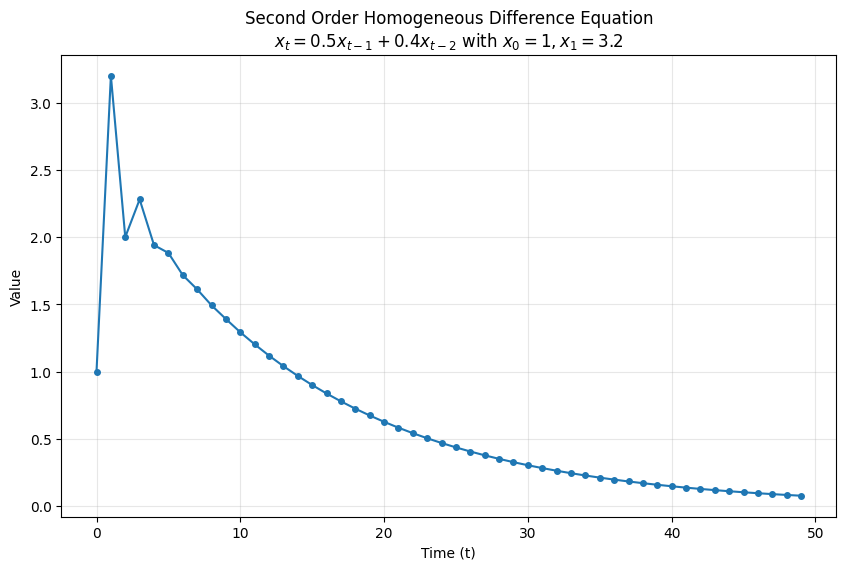

First 10 values:
x_0 = 1.0
x_1 = 3.2000
x_2 = 2.0000
x_3 = 2.2800
x_4 = 1.9400
x_5 = 1.8820
x_6 = 1.7170
x_7 = 1.6113
x_8 = 1.4925
x_9 = 1.3907


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
# Try changing the values here and see what happens in the plot
# does the sequence of values converge or does it explode?

phi_1 = 0.5
phi_2 = 0.4

# Initial conditions
x_0 = 1
x_1 = 3.2

# Number of time steps
T = 50
t = np.arange(T)

# Initialize array (we create an array of zeros with the size of T)
# We will use this to store the values of x_t when we compute them 
# in the following step

x = np.zeros(T)
x[0] = x_0
x[1] = x_1

# Now we start going through the values 
# For t = 2: x[2] = 0.5 * x[1] + 0.4 * x[0] (and store the result in x[2] so that the next iteration can access it)
# For t = 3: x[3] = 0.5 * x[2] + 0.4 * x[1] and compute x[3] (and store the result in x[3] for the same reason)
# and so on...

for i in range(2, T):
    x[i] = phi_1 * x[i-1] + phi_2 * x[i-2]

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(t, x, marker='o', markersize=4)
plt.title('Second Order Homogeneous Difference Equation\n' + 
          fr'$x_t = 0.5 x_{{t-1}} + 0.4 x_{{t-2}}$ with $x_0={x_0}, x_1={x_1}$')
plt.xlabel('Time (t)')
plt.ylabel('Value')
plt.grid(alpha=0.3)
plt.show()

# Print first few values to verify
print("First 10 values:")
print(f"x_0 = {x[0]}")
print(f"x_1 = {x[1]:.4f}")
print(f"x_2 = {x[2]:.4f}")
for i in range(3, 10):
    print(f"x_{i} = {x[i]:.4f}")

From the last equation and the simulation we can see that just as in the univariate case the stability of the system depends on the magnitude of the diagonal elements of the matrix $\mathbf{\Lambda}$. If these are 
between 0 and 1 in absolute value, the system will return to equilibrium after a shock in its initial conditions. Otherwise, it will show explosive behavior. So the key to studying
the stability is in the diagonal elements of the matrix $\mathbf{\Lambda}$. But how did we find these exactly? Here we need a little bit of linear algebra. It turns out that the diagonal elements of $\mathbf{\Lambda}$ are the eigenvalues of the matrix $\mathbf{A}$. But what are the eigenvalues?

Let's look at what a square matrix actually does when we multiply a vector by it.

Let's take the matrix from our example:

$$
\mathbf{A} = \begin{pmatrix}
0.5 & 0.4 \\
1 & 0
\end{pmatrix}
$$

and some vector $\mathbf{s}$:

$$
\mathbf{s} = \begin{pmatrix}
1 \\
1
\end{pmatrix}
$$

The result of the multiplication is a new vector of the same dimension as the original vector. This means that the matrix multiplication is mapping vector in $\mathbb{R}^2$ to $\mathbb{R}^2$, i.e. it keeps the dimensionality of the vector intact.

In [ ]:
#| label: fig-matrix-times-vector
#| fig-cap: "Multiplying matrix and a vector"

# Plot s = (1, 1) and As

import plotly.graph_objects as go
import numpy as np

# Define matrix A and vector s
A = np.array([[0.5, 0.4],
              [1.0, 0.0]])
s = np.array([1, 1])
As = A @ s

# Prepare origin and endpoint coordinates for the vectors
origin = np.array([0, 0])
vectors = np.stack([s, As], axis=0)

fig = go.Figure()

# Plot vector s
fig.add_trace(go.Scatter(x=[origin[0], s[0]],
                         y=[origin[1], s[1]],
                         mode='lines+markers+text',
                         marker=dict(size=7),
                         line=dict(width=3, color='blue'),
                         text=['', 's'],
                         textposition='top right',
                         name='s = (1,1)'))

# Plot vector As
fig.add_trace(go.Scatter(x=[origin[0], As[0]],
                         y=[origin[1], As[1]],
                         mode='lines+markers+text',
                         marker=dict(size=7),
                         line=dict(width=3, color='red'),
                         text=['', 'As'],
                         textposition='bottom left',
                         name='As'))

# Add grid and set axis aspect ratio to 1
fig.update_layout(
    title="Vector s and As under multiplication by A",
    xaxis=dict(title="x", zeroline=True, range=[-0.1, max(1, As[0]) + 0.2], dtick=0.2),
    yaxis=dict(title="y", zeroline=True, range=[-0.1, max(1, As[1]) + 0.2], dtick=0.2),
    showlegend=True,
    width=600, height=600
)
fig.update_yaxes(scaleanchor="x", scaleratio=1)
fig.show()


In [20]:
# Compute the matrix times the vector

(A @ s).round(2)

array([0.9, 1. ])

From @fig-matrix-times-vector you will see that the result of the matrix multiplication 
is another vector in the same space that is rotated a little bit. Not that obvious from the picture is that the length of the vector has changed as well.

In [ ]:
# Length of the original vector

print(np.linalg.norm(s))

# The length of the vector is computed by the theorem of Pythagoras (compare with the result above)

print(np.sqrt(s[0]**2 + s[1]**2))

# Length of the result vector

print(np.linalg.norm(As))
print(np.sqrt(As[0]**2 + As[1]**2))

1.4142135623730951
1.4142135623730951
1.3453624047073711
1.3453624047073711


There are two things to notice about these matrices. First, the middle matrix is a diagonal matrix (it has non-zero elements only on the main diagonal).
Second, not at all obvious thing is that if you multiply the first matrix on the right hand side with the last matrix on the right hand side
you will get the identity matrix (up to rounding errors).

In [ ]:
(G1 @ G2).round(1)

array([[ 1.,  0.],
       [-0.,  1.]])

$$
\mathbf{A} = \mathbf{E}\mathbf{L}\mathbf{E}^{-1}
$$

Here, $\mathbf{E}$ is the matrix of eigenvectors and $\mathbf{L}$ is the diagonal matrix of eigenvalues.

Using this decomposition, we can transform the complicated problem to a simple one with only diagonal entries in the matrix before $\mathbf{z}_{t - 1}$.

$$
\begin{align}
\mathbf{z}_{t} & = \mathbf{A} \mathbf{z}_{t - 1} + \mathbf{e}_{t} \\
\mathbf{z}_{t} & = \mathbf{E} \mathbf{L}\mathbf{E}^{-1} \mathbf{z}_{t - 1} + \mathbf{e}_{t} \\
\mathbf{E}^{-1} \mathbf{z}_{t} & = \mathbf{E}^{-1} \mathbf{E}\mathbf{L}\mathbf{E}^{-1} \mathbf{z}_{t - 1} + \mathbf{E}^{-1}\mathbf{e}_{t} \\
\mathbf{E}^{-1} \mathbf{z}_{t} & = \mathbf{L}\mathbf{E}^{-1} \mathbf{z}_{t - 1} + \mathbf{E}^{-1}\mathbf{e}_{t} \\
\tilde{\mathbf{z}}_{t} & = \mathbf{L} \tilde{\mathbf{z}}_{t - 1} + \tilde{\mathbf{e}_{t}}
\end{align}
$$

Now, we can solve the difference equation in the simple case. Once we have found the
solutions, we can transform them back to the original variables $x_t$ and $y_t$.

For the purposes of this course, however, our focus lies on the behavior 
of the system: Does it converge to a stable path?

The answer is in the matrix $\mathbf{A}$. When we start doing the
the recursive substitution that we did in the scalar case, the transformed equations
will look like this:

$$
\begin{align}
\tilde{\mathbf{z}}_{t} & = \mathbf{L} \tilde{\mathbf{z}}_{t - 1} + \tilde{\mathbf{e}}_{t} \\
\tilde{\mathbf{z}}_{t + 1} & = \mathbf{L} (\mathbf{L} \tilde{\mathbf{z}}_{t - 1} + \tilde{\mathbf{e}}_{t}) + \tilde{\mathbf{e}}_{t + 1} \\
\implies \tilde{\mathbf{z}}_{t + 1} & = \mathbf{L}^2 \tilde{\mathbf{z}}_{t - 1} +\mathbf{L} \tilde{\mathbf{e}}_{t} + \tilde{\mathbf{e}}_{t + 1}\\
\tilde{\mathbf{z}}_{t + j} & = \mathbf{L}^{j + 1} \tilde{\mathbf{z}}_{t - 1} + \sum_{k = 0}^{j} \mathbf{L}^{k} \tilde{\mathbf{e}}_{t + j - k}
\end{align}
$$

You can continue the substitution just like we did in @exr-autonomous-solution. At this
point, you should realize that the system's behavior depends on the matrix $\mathbf{L}$. If the elements of $\mathbf{L}$ are less than one in absolute value, the system will return to equilibrium after a shock. Otherwise, it will show explosive behavior. This
leads us to the following problem: How do we find the values of the diagonal matrix? We will make
use of a result from linear algebra.

:::{#thm-eigenvalues}
## Eigenvalues

From the illustrations above it should be clear that the matrix only stretches (or shrinks) in the directions of the eigenvectors. This basically means that the whole matrix-vector product acts as a scalar multiplication (in the direction of the eigenvector).

$$
\begin{align*}
\mathbf{A} \mathbf{e} & = \lambda \mathbf{e} \\
\mathbf{A} \mathbf{e} - \lambda \mathbf{e} & = 0 \\
\mathbf{A} \mathbf{e} - \lambda \mathbf{I} \mathbf{e} & = 0 \\
(\mathbf{A} - \lambda \mathbf{I}) \mathbf{e} & = 0
\end{align*}
$$

The last equation shows something interesting. A matrix ($\mathbf{A} - \lambda \mathbf{I}$) takes a vector ($\mathbf{e}$) and maps it to the zero vector. However, this means that the matrix is special (this is a property called singularity). "Normal" matrices take a vector and map it to another vector in the same space. But singular matrices can take a vector and map it to the zero vector. We can use this property to find the eigenvalues of a matrix. A singular matrix has a determinant of zero which leads us to the following equation that we can solve for $\lambda$:

$$
\det(\mathbf{A} - \lambda\mathbf{I}) = 0
$$
:::

In [3]:
phi_1 = 0.5
phi_2 = 0.4

A = np.array([[phi_1, phi_2], [1, 0]])
eigenvalues, eigenvectors = np.linalg.eig(A)
E = eigenvectors
L = np.diag(eigenvalues)

print("Eigenvalue matrix L:")
print(L)
print("Inverse eigenvector matrix E:")
print(np.linalg.inv(E))
print("Eigenvector matrix E:")
print(E)
print("Reconstructed A:")
E @ L @ np.linalg.inv(E)


Eigenvalue matrix L:
[[ 0.93007353  0.        ]
 [ 0.         -0.43007353]]
Inverse eigenvector matrix E:
[[ 1.00405577  0.4318178 ]
 [-0.80032535  0.74436142]]
Eigenvector matrix E:
[[ 0.68104151 -0.39508475]
 [ 0.73224481  0.91864467]]
Reconstructed A:


array([[5.00000000e-01, 4.00000000e-01],
       [1.00000000e+00, 6.13993543e-17]])